# LABORATORY 06 - Explainable GeoAI

## Why does the frozen prospectivity model rank a cell highly?

This executed notebook turns the validated LABORATORY 05
prospectivity model into a layered explainability analysis.

The predictive model is **not reselected** here. Every explanation
inherits the frozen Feature Set A + Logistic Regression contract,
the out-of-sample candidate-ranking design, and the sealed hidden
oracle boundary.

**Interpretation boundary:** coefficients, permutation importance,
and SHAP describe model associations and attribution. They are not
causal effects, and the prospectivity score is not a calibrated
probability of mineral occurrence.

## Reading guide

The notebook follows one question through progressively richer
evidence:

**Frozen model -> global drivers -> local explanations -> spatial
attribution -> stability -> scientific interpretation**

The visual system uses a warm-neutral analytical canvas, trust-blue
structure, and a restrained coral accent for the primary insight.
Diverging attribution plots reuse the same blue-to-coral semantics,
while driver families keep stable categorical colors throughout.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import MaxNLocator

%matplotlib inline

LAB_DIR = Path.cwd()
if LAB_DIR.name != "lab06_explainable_geoai":
    candidate = Path("labs/lab06_explainable_geoai")
    if candidate.exists():
        LAB_DIR = candidate.resolve()

RESULTS_DIR = LAB_DIR / "results"
LAB05_RESULTS = (
    LAB_DIR.parent
    / "lab05_mineral_prospectivity"
    / "results"
)

assert RESULTS_DIR.exists(), RESULTS_DIR
assert LAB05_RESULTS.exists(), LAB05_RESULTS

plt.rcParams.update(
    {
        "figure.facecolor": "#F7F5F2",
        "axes.facecolor": "#F7F5F2",
        "axes.edgecolor": "#B8C2CC",
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 15,
        "axes.titlepad": 18,
        "axes.labelsize": 10.5,
        "font.size": 10.5,
        "legend.frameon": False,
        "grid.color": "#D9E2EC",
        "grid.linewidth": 0.7,
        "grid.alpha": 0.48,
        "figure.dpi": 120,
        "savefig.dpi": 150,
    }
)

BG = "#F7F5F2"
PANEL = "#EFEAE4"
INK = "#1F2933"
MUTED = "#7B8794"
GRID = "#D9E2EC"
TRUST = "#355C7D"
TRUST_DARK = "#243B53"
ACCENT = "#C44536"
ACCENT_DARK = "#9E2F25"
ACCENT_SOFT = "#E5B5AE"
TEAL = "#3C7E74"
OCHRE = "#C49A3A"
STONE = "#8D7F70"
NEUTRAL = "#D8D2CB"
STEEL = TRUST
NEGATIVE = "#4C78A8"
POSITIVE = ACCENT

METHOD_COLORS = {
    "Coefficient": STONE,
    "Permutation": "#5F7D95",
    "SHAP": ACCENT,
}

FAMILY_COLORS = {
    "intrusive": ACCENT,
    "structure": "#5F7D95",
    "lithology": STONE,
    "alteration": OCHRE,
    "geophysics": TEAL,
}

XAI_DIVERGING = LinearSegmentedColormap.from_list(
    "xai_diverging",
    [NEGATIVE, BG, ACCENT],
)

RANK_SEQUENTIAL = LinearSegmentedColormap.from_list(
    "rank_sequential",
    ["#F6EFE7", "#E9B872", "#D97706", "#B23A2B"],
)

FEATURE_LABELS = {
    "lithology": "Lithology",
    "distance_to_intrusive_m": "Distance to intrusive",
    "intrusive_affinity": "Intrusive affinity",
    "distance_to_fault_m": "Distance to fault",
    "distance_to_fault_intersection_m": "Fault-intersection distance",
    "distance_to_contact_m": "Contact distance",
    "magnetic_anomaly": "Magnetic anomaly",
    "gravity_anomaly": "Gravity anomaly",
    "alteration_index": "Alteration index",
}

CASE_LABELS = {
    "top_candidate": "Rank 1",
    "top_1pct_boundary": "Top 1% boundary",
    "top_5pct_boundary": "Top 5% boundary",
    "median_candidate": "Median candidate",
    "lowest_candidate": "Rank 6300",
}

def load_csv(name):
    path = RESULTS_DIR / name
    assert path.exists(), path
    return pd.read_csv(path)

def load_json(name):
    path = RESULTS_DIR / name
    assert path.exists(), path
    return json.loads(path.read_text(encoding="utf-8"))

def pretty_feature(value):
    return FEATURE_LABELS.get(str(value), str(value))

def format_table(frame, formats=None):
    formats = formats or {}
    shown = frame.copy()

    for column, formatter in formats.items():
        if column in shown.columns:
            shown[column] = shown[column].map(formatter)

    html = shown.to_html(
        index=False,
        border=0,
        escape=False,
        classes="portfolio-table",
    )

    css = '''
    <style>
    .portfolio-table {
        border-collapse: collapse;
        width: 100%;
        font-family: Arial, sans-serif;
        font-size: 13px;
        margin: 8px 0 4px 0;
    }
    .portfolio-table thead th {
        background: #243B53;
        color: #FFFFFF;
        font-weight: 600;
        padding: 8px 10px;
        text-align: left;
        border: 0;
    }
    .portfolio-table tbody td {
        background: #F7F5F2;
        color: #1F2933;
        padding: 7px 10px;
        border-bottom: 1px solid #D9E2EC;
        vertical-align: top;
    }
    .portfolio-table tbody tr:nth-child(even) td {
        background: #EFEAE4;
    }
    .portfolio-table tbody tr:hover td {
        background: #E7EDF2;
    }
    </style>
    '''

    display(HTML(css + html))

def clean_axis(ax):
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)

print("LAB06_NOTEBOOK_ARTIFACT_LAYER = READY")

LAB06_NOTEBOOK_ARTIFACT_LAYER = READY


In [2]:
coefficient = load_csv("coefficient_summary.csv")
permutation = load_csv("permutation_importance_summary.csv")
shap_global = load_csv("shap_global_raw.csv")
shap_sample = load_csv("shap_global_sample.csv")
local_cases = load_csv("local_explanation_cases.csv")
local = load_csv("local_shap_contributions.csv")
local_replicates = load_csv("local_shap_replicates.csv")
dominant = load_csv("dominant_driver_by_cell.csv")
spatial = pd.read_csv(
    RESULTS_DIR / "spatial_shap_contributions.csv.gz",
    compression="gzip",
)
stability = load_csv("explanation_stability_summary.csv")
rank_agreement = load_csv("explanation_rank_agreement.csv")
method_agreement = load_csv("explanation_method_agreement.csv")
family_stability = load_csv("driver_family_stability.csv")

phase_b_manifest = load_json(
    "model_reconstruction_manifest.json"
)
phase_c_manifest = load_json("global_shap_manifest.json")
phase_d_manifest = load_json(
    "spatial_explainability_manifest.json"
)
phase_e_manifest = load_json(
    "explanation_stability_manifest.json"
)

assert phase_b_manifest["status"] == "PASS"
assert phase_b_manifest["model_reselected"] is False
assert phase_c_manifest["oracle_loaded"] is False
assert phase_d_manifest["oracle_loaded"] is False
assert phase_e_manifest["oracle_loaded"] is False

assert len(local_cases) == 5
assert len(spatial) == 56700
assert len(dominant) == 6300
assert len(stability) == 9

print("LAB06_NOTEBOOK_DATA_QA = PASS")
print("candidate cells:", len(dominant))
print("spatial contribution rows:", len(spatial))
print("OOS SHAP explanations:", phase_e_manifest["total_oos_explanations"])

LAB06_NOTEBOOK_DATA_QA = PASS
candidate cells: 6300
spatial contribution rows: 56700
OOS SHAP explanations: 58000


## 1. Frozen explanation contract

Explainability is evaluated **after** predictive model selection.
The laboratory therefore asks why the frozen model behaves as it
does without allowing explanation outputs to change the model.

In [3]:
contract_table = pd.DataFrame(
    [
        ["Operational model", "Logistic Regression"],
        ["Feature set", "Feature Set A / 9 raw predictors"],
        ["Background replicates", "10"],
        ["Training rows per replicate", "600"],
        ["OOS candidates per replicate", "5,800"],
        ["Total OOS explanations", "58,000"],
        ["SHAP output space", "Log-odds"],
        ["Hidden oracle used", "No"],
        ["Model reselected", "No"],
        ["Score semantics", "Prospectivity ranking score"],
    ],
    columns=["Contract item", "Validated setting"],
)

format_table(contract_table)

Contract item,Validated setting
Operational model,Logistic Regression
Feature set,Feature Set A / 9 raw predictors
Background replicates,10
Training rows per replicate,600
OOS candidates per replicate,"5,800"
Total OOS explanations,"58,000"
SHAP output space,Log-odds
Hidden oracle used,No
Model reselected,No
Score semantics,Prospectivity ranking score


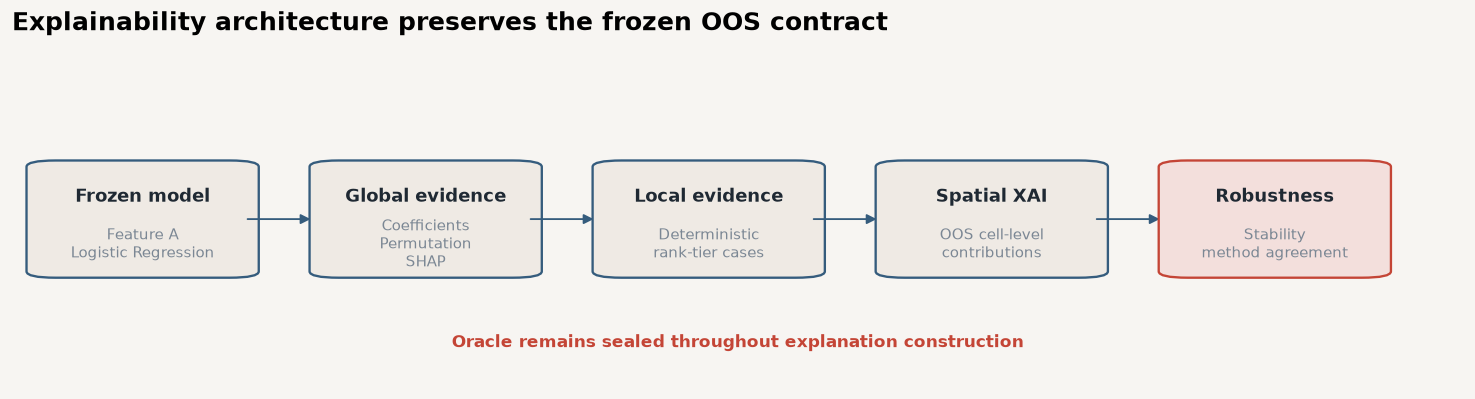

In [4]:
fig, ax = plt.subplots(figsize=(12.8, 4.0))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

stages = [
    (0.025, "Frozen model", "Feature A\nLogistic Regression"),
    (0.220, "Global evidence", "Coefficients\nPermutation\nSHAP"),
    (0.415, "Local evidence", "Deterministic\nrank-tier cases"),
    (0.610, "Spatial XAI", "OOS cell-level\ncontributions"),
    (0.805, "Robustness", "Stability\nmethod agreement"),
]

for index, (x, title, subtitle) in enumerate(stages):
    width = 0.13
    box = FancyBboxPatch(
        (x, 0.36),
        width,
        0.34,
        boxstyle="round,pad=0.015,rounding_size=0.02",
        facecolor=PANEL if index != 4 else "#F3DFDC",
        edgecolor=ACCENT if index == 4 else TRUST,
        linewidth=1.4,
    )
    ax.add_patch(box)
    ax.text(
        x + width / 2,
        0.60,
        title,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        x + width / 2,
        0.45,
        subtitle,
        ha="center",
        va="center",
        fontsize=9,
        color=MUTED,
    )

    if index < len(stages) - 1:
        next_x = stages[index + 1][0]
        arrow = FancyArrowPatch(
            (x + width + 0.005, 0.53),
            (next_x - 0.012, 0.53),
            arrowstyle="-|>",
            mutation_scale=12,
            linewidth=1.1,
            color=TRUST,
        )
        ax.add_patch(arrow)

ax.text(
    0.5,
    0.14,
    "Oracle remains sealed throughout explanation construction",
    ha="center",
    va="center",
    fontsize=10,
    color=ACCENT,
    fontweight="bold",
)
ax.set_title(
    "Explainability architecture preserves the frozen OOS contract",
    loc="left",
    pad=24,
)
fig.subplots_adjust(
    left=0.04,
    right=0.985,
    top=0.82,
    bottom=0.16,
)
plt.show()

**Takeaway.** The notebook is an interpretation layer over a frozen
predictive workflow. It is not a second model-selection exercise.

## 2. Global drivers: three complementary lenses

Coefficients describe the standardized linear model, permutation
importance measures held-out performance degradation, and SHAP
decomposes the model output. Agreement is useful; disagreement is
also scientifically informative because correlated predictors can
redistribute attribution.

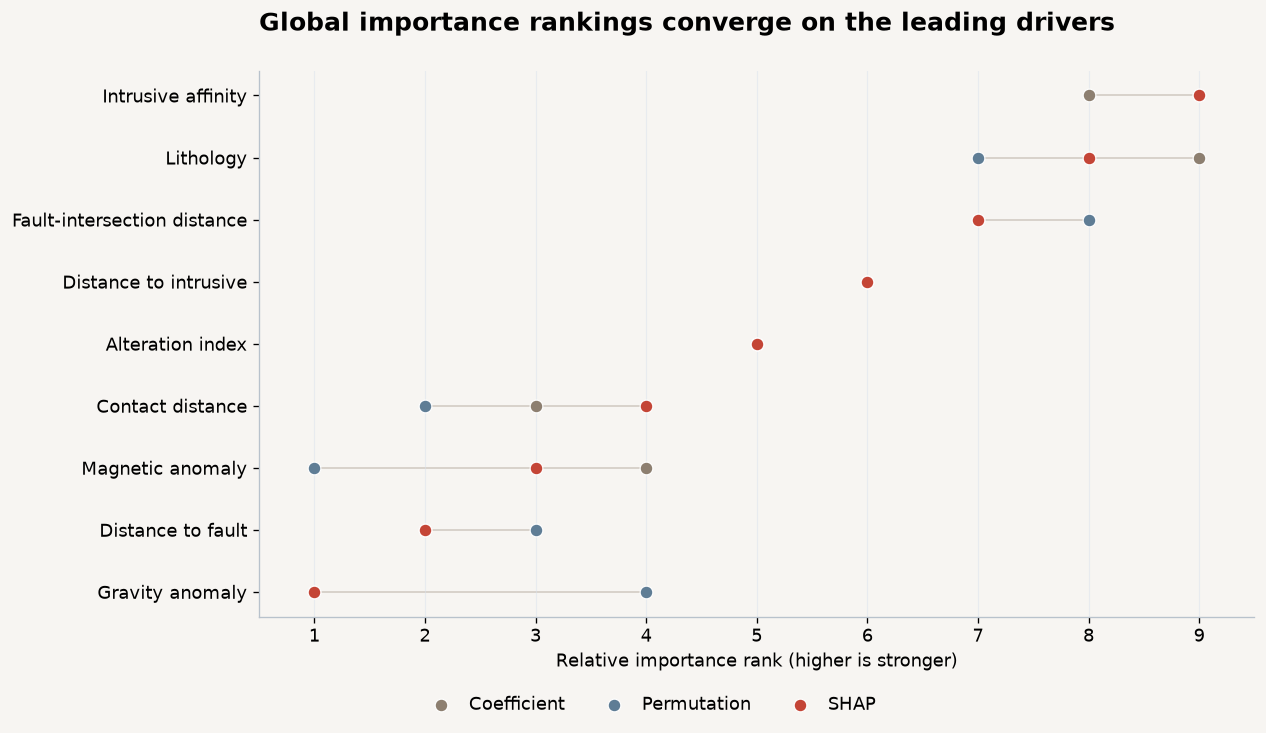

In [5]:
comparison = rank_agreement.copy()

methods = [
    (
        "coefficient_rank",
        "Coefficient",
        METHOD_COLORS["Coefficient"],
    ),
    (
        "permutation_rank",
        "Permutation",
        METHOD_COLORS["Permutation"],
    ),
    (
        "shap_rank",
        "SHAP",
        METHOD_COLORS["SHAP"],
    ),
]

comparison["label"] = comparison["feature"].map(pretty_feature)
comparison = comparison.sort_values("shap_rank", ascending=False)

fig, ax = plt.subplots(figsize=(10.5, 6.5))

y = np.arange(len(comparison))

for position in y:
    row = comparison.iloc[position]
    scores = [
        10 - row["coefficient_rank"],
        10 - row["permutation_rank"],
        10 - row["shap_rank"],
    ]
    ax.plot(
        [min(scores), max(scores)],
        [position, position],
        color=NEUTRAL,
        linewidth=1.2,
        zorder=1,
    )

for column, label, color in methods:
    ax.scatter(
        10 - comparison[column],
        y,
        s=58,
        label=label,
        color=color,
        edgecolor="white",
        linewidth=0.7,
        zorder=3,
    )

ax.set_yticks(y)
ax.set_yticklabels(comparison["label"])
ax.set_xlabel("Relative importance rank (higher is stronger)")
ax.set_xlim(0.5, 9.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
clean_axis(ax)
ax.set_title(
    "Global importance rankings converge on the leading drivers",
    loc="left",
    pad=24,
)
handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=3,
    frameon=False,
    columnspacing=1.8,
    handletextpad=0.6,
)
fig.subplots_adjust(
    left=0.19,
    right=0.98,
    top=0.86,
    bottom=0.16,
)
plt.show()

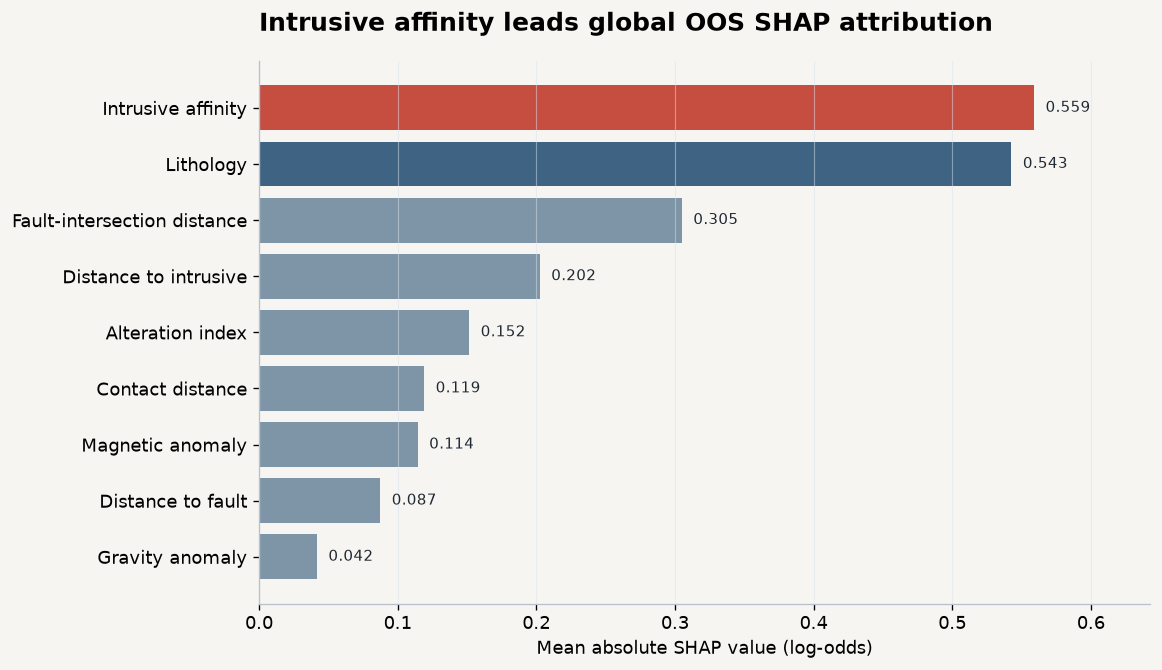

In [6]:
global_plot = shap_global.sort_values(
    "mean_abs_shap",
    ascending=True,
).copy()
global_plot["label"] = global_plot["raw_feature"].map(
    pretty_feature
)

fig, ax = plt.subplots(figsize=(9.8, 5.7))
bars = ax.barh(
    global_plot["label"],
    global_plot["mean_abs_shap"],
    color=[
        ACCENT
        if feature == "intrusive_affinity"
        else TRUST
        if feature == "lithology"
        else "#7890A4"
        for feature in global_plot["raw_feature"]
    ],
    alpha=0.95,
)

for bar, value in zip(
    bars,
    global_plot["mean_abs_shap"],
    strict=True,
):
    ax.text(
        value + global_plot["mean_abs_shap"].max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=9,
        color=INK,
    )

clean_axis(ax)
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_title(
    "Intrusive affinity leads global OOS SHAP attribution",
    loc="left",
)
ax.set_xlim(
    0,
    global_plot["mean_abs_shap"].max() * 1.15,
)
fig.tight_layout()
plt.show()

The strongest global SHAP drivers are intrusive affinity,
lithology, and distance to fault intersections. SHAP magnitude
describes model attribution in log-odds space; it does not imply
geological causation.

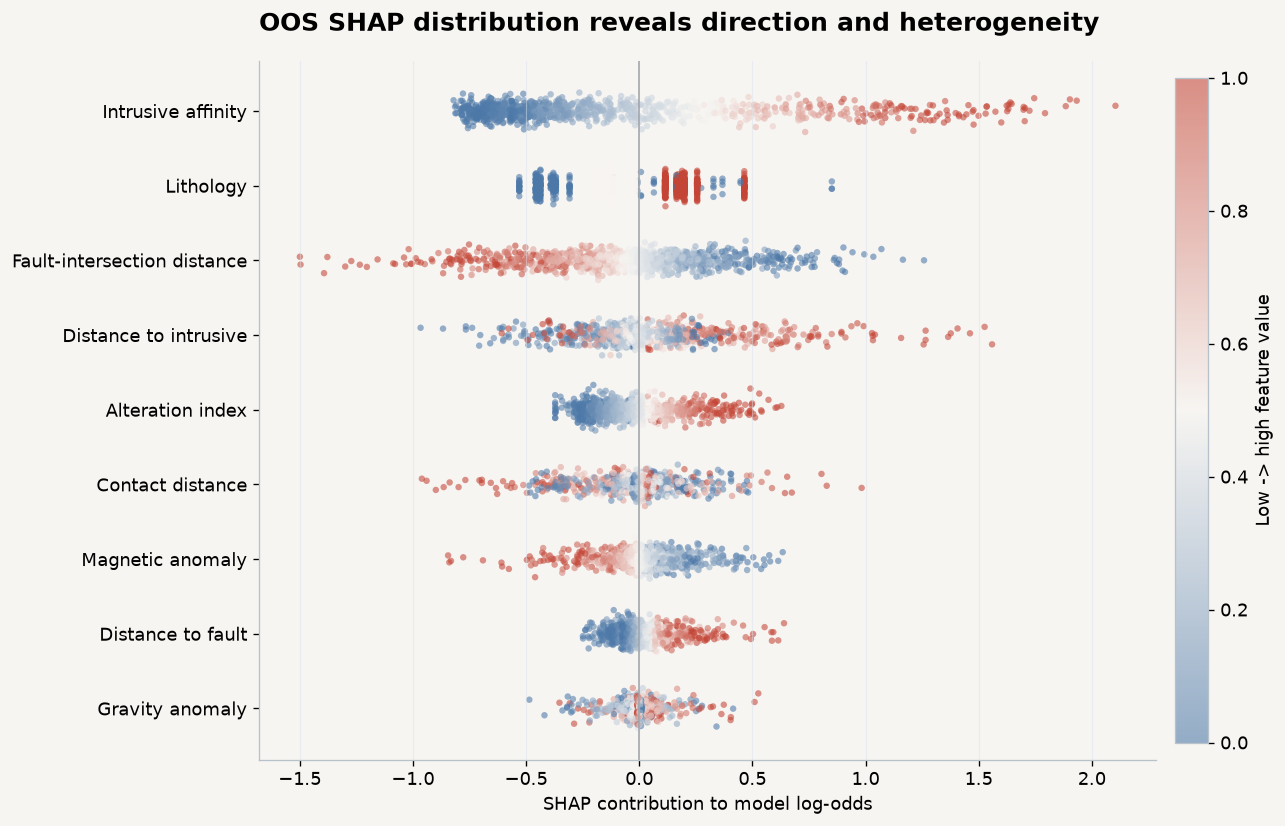

In [7]:
numeric = shap_sample.loc[
    shap_sample["raw_feature"] != "lithology"
].copy()

numeric_grouped = (
    numeric.groupby(
        ["replicate", "cell_id", "raw_feature"],
        as_index=False,
    )
    .agg(
        shap_value=("shap_value", "sum"),
        display_value=("transformed_value", "mean"),
    )
)

lithology = shap_sample.loc[
    shap_sample["raw_feature"] == "lithology"
].copy()

lithology_shap = (
    lithology.groupby(
        ["replicate", "cell_id"],
        as_index=False,
    )["shap_value"]
    .sum()
)

active_lithology = (
    lithology.loc[lithology["transformed_value"] > 0.5]
    .assign(
        category=lambda x: x["transformed_feature"]
        .str.replace("lithology_", "", regex=False)
    )
    [["replicate", "cell_id", "category"]]
)

category_order = {
    value: index
    for index, value in enumerate(
        sorted(active_lithology["category"].unique())
    )
}

active_lithology["display_value"] = active_lithology[
    "category"
].map(category_order)

lithology_grouped = lithology_shap.merge(
    active_lithology[
        ["replicate", "cell_id", "display_value"]
    ],
    on=["replicate", "cell_id"],
    how="left",
    validate="one_to_one",
)
lithology_grouped["raw_feature"] = "lithology"

beeswarm = pd.concat(
    [numeric_grouped, lithology_grouped],
    ignore_index=True,
)

order = list(
    shap_global.sort_values("mean_abs_shap")[
        "raw_feature"
    ]
)

rng = np.random.default_rng(12345)

fig, ax = plt.subplots(figsize=(10.8, 7.0))

for y_index, feature in enumerate(order):
    subset = beeswarm.loc[
        beeswarm["raw_feature"] == feature
    ].copy()

    values = subset["display_value"].to_numpy(dtype=float)
    finite = np.isfinite(values)

    color_value = np.full(len(subset), 0.5)

    if finite.any():
        valid = values[finite]
        low = np.nanpercentile(valid, 5)
        high = np.nanpercentile(valid, 95)

        if high > low:
            color_value[finite] = np.clip(
                (valid - low) / (high - low),
                0,
                1,
            )

    jitter = rng.normal(0, 0.085, len(subset))

    scatter = ax.scatter(
        subset["shap_value"],
        y_index + jitter,
        c=color_value,
        cmap=XAI_DIVERGING,
        vmin=0,
        vmax=1,
        s=15,
        alpha=0.58,
        linewidth=0,
        rasterized=True,
    )

ax.axvline(0, color="#9da1a6", linewidth=0.9)
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels([pretty_feature(x) for x in order])
ax.set_xlabel("SHAP contribution to model log-odds")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title(
    "OOS SHAP distribution reveals direction and heterogeneity",
    loc="left",
)

cbar = fig.colorbar(
    scatter,
    ax=ax,
    pad=0.02,
    fraction=0.035,
)
cbar.set_label("Low -> high feature value")

fig.tight_layout()
plt.show()

## 3. Cross-method agreement

Agreement is summarized using the rank order of the nine raw
variables. Top-k overlap is especially useful because exploration
decisions often focus on a small set of dominant drivers.

In [8]:
agreement_table = method_agreement.copy()
agreement_table["Comparison"] = (
    agreement_table["method_left"].str.title()
    + " vs "
    + agreement_table["method_right"].str.title()
)

agreement_table = agreement_table[
    [
        "Comparison",
        "spearman_rank_correlation",
        "top3_jaccard",
        "top5_jaccard",
    ]
].rename(
    columns={
        "spearman_rank_correlation": "Spearman rho",
        "top3_jaccard": "Top-3 overlap",
        "top5_jaccard": "Top-5 overlap",
    }
)

format_table(
    agreement_table,
    {
        "Spearman rho": lambda x: f"{x:.3f}",
        "Top-3 overlap": lambda x: f"{x:.0%}",
        "Top-5 overlap": lambda x: f"{x:.0%}",
    },
)

Comparison,Spearman rho,Top-3 overlap,Top-5 overlap
Coefficient vs Permutation,0.783,100%,100%
Coefficient vs Shap,0.967,100%,100%
Permutation vs Shap,0.833,100%,100%


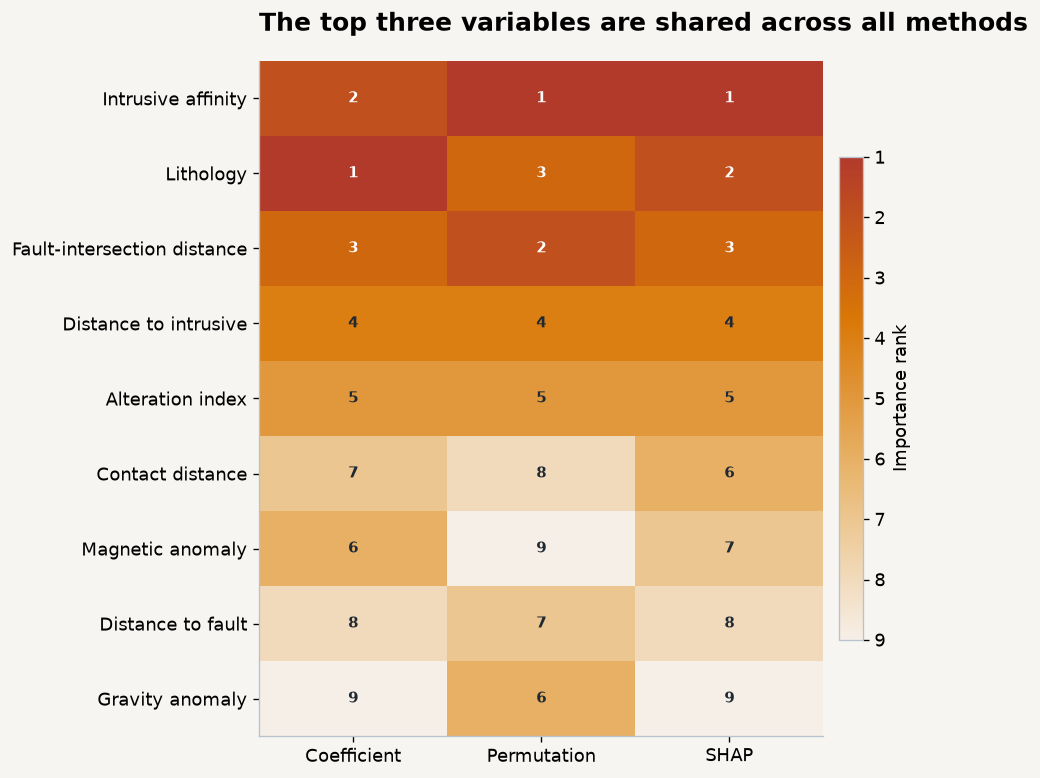

In [9]:
matrix = rank_agreement[
    [
        "coefficient_rank",
        "permutation_rank",
        "shap_rank",
    ]
].to_numpy(dtype=float)

labels = [
    pretty_feature(x)
    for x in rank_agreement["feature"]
]

fig, ax = plt.subplots(figsize=(7.8, 6.6))
image = ax.imshow(
    matrix,
    aspect="auto",
    cmap=RANK_SEQUENTIAL.reversed(),
    vmin=1,
    vmax=9,
)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(
    ["Coefficient", "Permutation", "SHAP"]
)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels)

for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = int(matrix[row, column])
        ax.text(
            column,
            row,
            str(value),
            ha="center",
            va="center",
            color=(
                "white"
                if value <= 3
                else INK
            ),
            fontweight="bold",
            fontsize=9,
        )

cbar = fig.colorbar(
    image,
    ax=ax,
    pad=0.025,
    fraction=0.04,
)
cbar.set_label("Importance rank")
cbar.ax.invert_yaxis()

ax.set_title(
    "The top three variables are shared across all methods",
    loc="left",
)
fig.tight_layout()
plt.show()

## 4. Local explanations

Five cells were fixed in advance by candidate rank: rank 1, the
top-1% boundary, the top-5% boundary, the median candidate, and
rank 6300. No cell was selected after viewing its explanation.

In [10]:
cases_table = local_cases.copy()
cases_table["Case"] = cases_table["case_label"].map(CASE_LABELS)
cases_table = cases_table[
    [
        "Case",
        "cell_id",
        "candidate_rank",
        "prospectivity_score_oos_mean",
        "oos_model_count",
    ]
].rename(
    columns={
        "cell_id": "Cell",
        "candidate_rank": "Rank",
        "prospectivity_score_oos_mean": "Mean OOS score",
        "oos_model_count": "OOS models",
    }
)

format_table(
    cases_table,
    {
        "Mean OOS score": lambda x: f"{x:.3f}",
        "Rank": lambda x: f"{int(x):,}",
        "OOS models": lambda x: f"{int(x)}",
    },
)

Case,Cell,Rank,Mean OOS score,OOS models
Rank 1,3876,1,0.686,8
Top 1% boundary,4774,63,0.578,10
Top 5% boundary,4106,315,0.469,10
Median candidate,1501,"3,150",0.088,8
Rank 6300,6079,"6,300",0.028,9


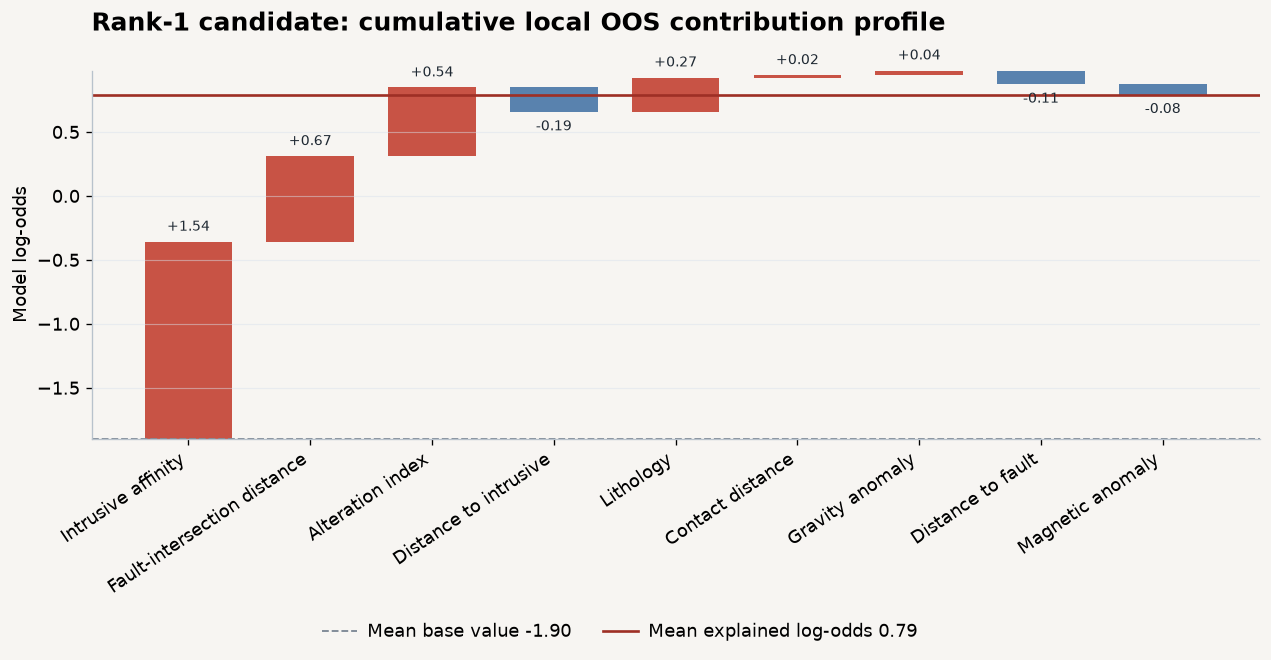

In [11]:
case_name = "top_candidate"
case_local = (
    local.loc[local["case_label"] == case_name]
    .sort_values("mean_abs_shap", ascending=False)
    .copy()
)

case_rep = local_replicates.loc[
    local_replicates["case_label"] == case_name
]

base_value = case_rep.groupby("replicate")[
    "base_value"
].first().mean()

decision_value = case_rep.groupby("replicate")[
    "decision_function"
].first().mean()

contributions = case_local[
    "mean_signed_shap"
].to_numpy(dtype=float)
labels = [
    pretty_feature(x)
    for x in case_local["feature"]
]

running = base_value + np.r_[
    0,
    np.cumsum(contributions[:-1]),
]

fig, ax = plt.subplots(figsize=(11.0, 5.9))

x = np.arange(len(contributions))

for index, (value, bottom) in enumerate(
    zip(contributions, running, strict=True)
):
    ax.bar(
        index,
        value,
        bottom=bottom,
        width=0.72,
        color=POSITIVE if value >= 0 else NEGATIVE,
        alpha=0.92,
    )
    ax.text(
        index,
        bottom + value + (
            0.06 if value >= 0 else -0.06
        ),
        f"{value:+.2f}",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=8.5,
        color=INK,
    )

ax.axhline(
    base_value,
    color=MUTED,
    linestyle="--",
    linewidth=1.1,
    label=f"Mean base value {base_value:.2f}",
)
ax.axhline(
    decision_value,
    color=ACCENT_DARK,
    linewidth=1.6,
    label=f"Mean explained log-odds {decision_value:.2f}",
)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=34, ha="right")
ax.set_ylabel("Model log-odds")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
ax.set_title(
    "Rank-1 candidate: cumulative local OOS contribution profile",
    loc="left",
    pad=24,
)
handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.012),
    ncol=2,
    frameon=False,
    columnspacing=1.8,
    handletextpad=0.6,
)
fig.subplots_adjust(
    left=0.10,
    right=0.985,
    top=0.84,
    bottom=0.32,
)
plt.show()

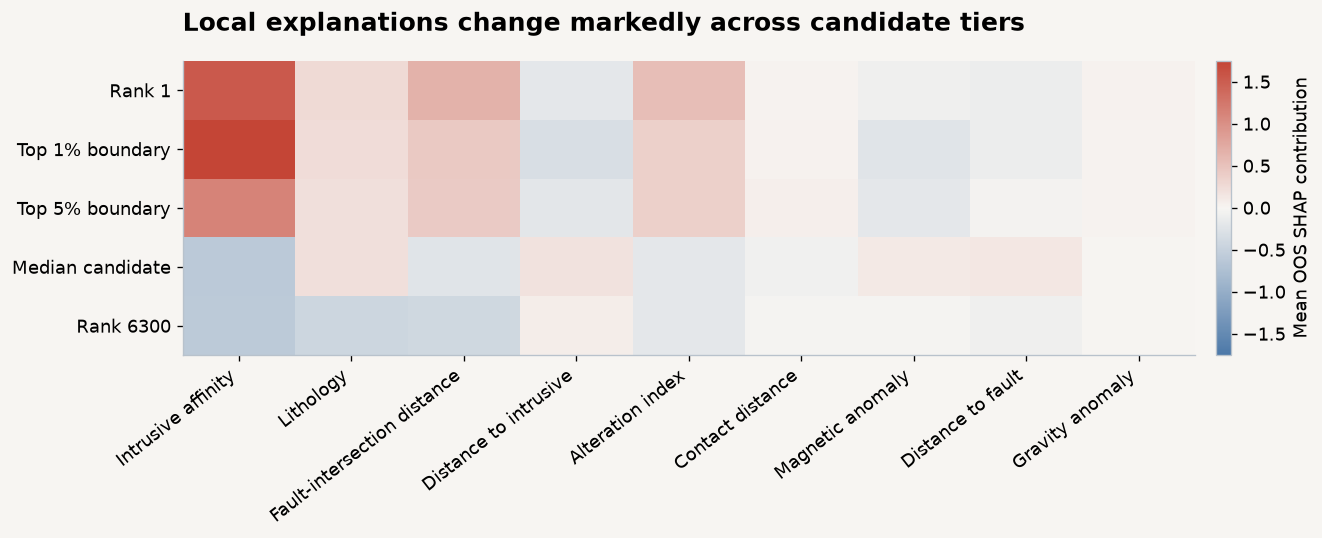

In [12]:
heat = (
    local.pivot(
        index="case_label",
        columns="feature",
        values="mean_signed_shap",
    )
    .reindex(
        [
            "top_candidate",
            "top_1pct_boundary",
            "top_5pct_boundary",
            "median_candidate",
            "lowest_candidate",
        ]
    )
)

feature_order = list(
    shap_global.sort_values("mean_abs_shap", ascending=False)[
        "raw_feature"
    ]
)
heat = heat[feature_order]

limit = float(np.nanmax(np.abs(heat.to_numpy())))

fig, ax = plt.subplots(figsize=(11.2, 4.6))
image = ax.imshow(
    heat.to_numpy(),
    aspect="auto",
    cmap=XAI_DIVERGING,
    vmin=-limit,
    vmax=limit,
)

ax.set_xticks(np.arange(len(feature_order)))
ax.set_xticklabels(
    [pretty_feature(x) for x in feature_order],
    rotation=38,
    ha="right",
)
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(
    [CASE_LABELS[x] for x in heat.index]
)

cbar = fig.colorbar(
    image,
    ax=ax,
    pad=0.02,
    fraction=0.035,
)
cbar.set_label("Mean OOS SHAP contribution")

ax.set_title(
    "Local explanations change markedly across candidate tiers",
    loc="left",
)
fig.tight_layout()
plt.show()

**Takeaway.** A high global importance does not imply the same
local direction everywhere. The rank-tier comparison exposes where
the same variable supports or suppresses a candidate score.

## 5. Spatial explainability

Each candidate cell is explained only by replicate models in which
that cell was out of sample. The spatial maps therefore inherit the
same OOS ensemble semantics used by the prospectivity ranking.

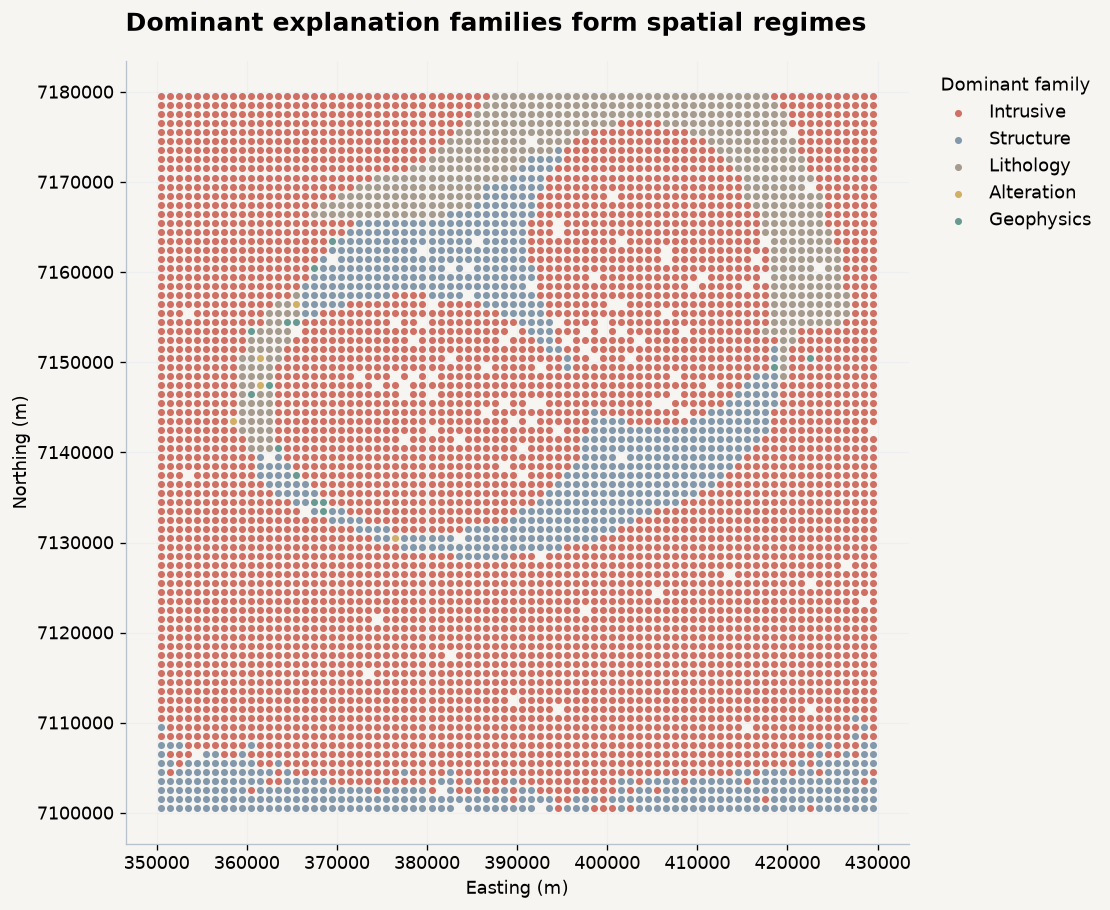

In [13]:
family_order = [
    "intrusive",
    "structure",
    "lithology",
    "alteration",
    "geophysics",
]

fig, ax = plt.subplots(figsize=(9.2, 7.7))

for family in family_order:
    subset = dominant.loc[
        dominant["dominant_family"] == family
    ]
    ax.scatter(
        subset["Easting"],
        subset["Northing"],
        s=18,
        color=FAMILY_COLORS[family],
        alpha=0.76,
        linewidth=0,
        label=family.title(),
    )

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.ticklabel_format(
    style="plain",
    axis="both",
    useOffset=False,
)
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    title="Dominant family",
)
ax.grid(alpha=0.28)
ax.set_title(
    "Dominant explanation families form spatial regimes",
    loc="left",
)
fig.tight_layout()
plt.show()

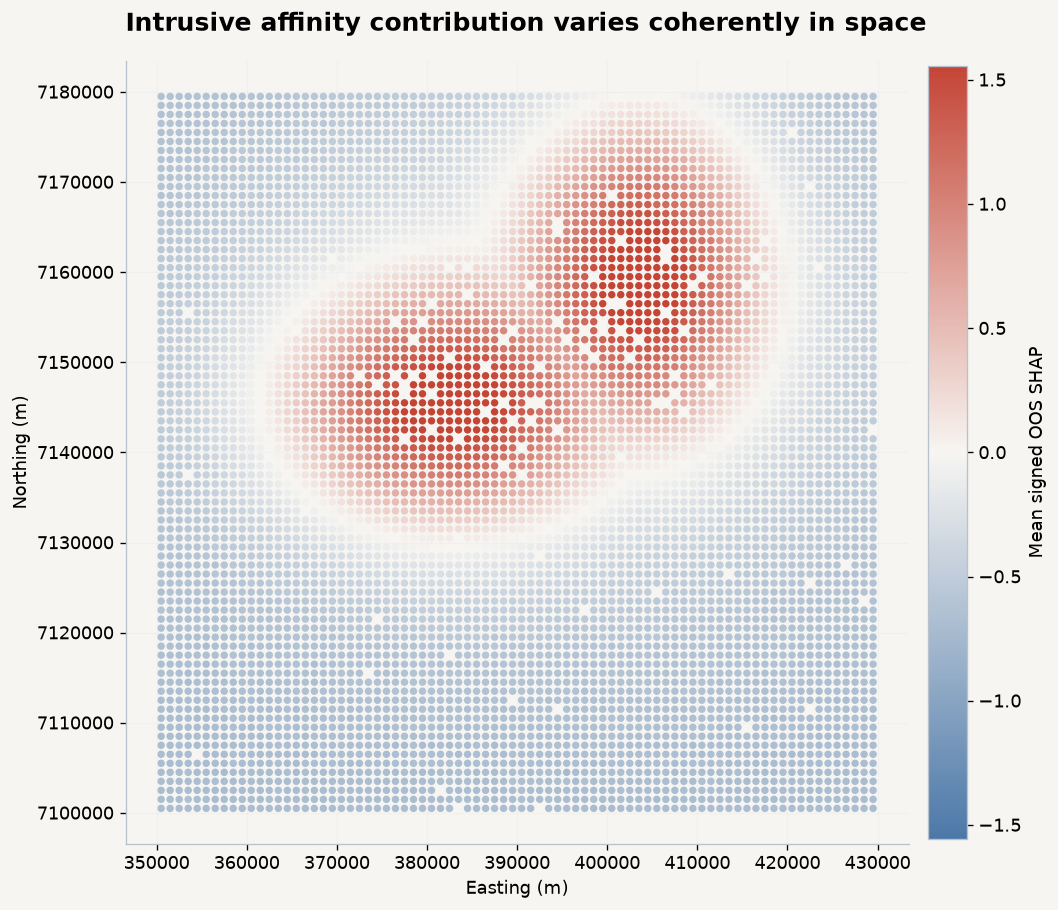

In [14]:
spatial_feature = "intrusive_affinity"
map_frame = spatial.loc[
    spatial["feature"] == spatial_feature
].copy()

limit = float(
    np.nanpercentile(
        np.abs(map_frame["mean_signed_shap"]),
        98,
    )
)

fig, ax = plt.subplots(figsize=(9.2, 7.7))
scatter = ax.scatter(
    map_frame["Easting"],
    map_frame["Northing"],
    c=map_frame["mean_signed_shap"],
    cmap=XAI_DIVERGING,
    vmin=-limit,
    vmax=limit,
    s=20,
    linewidth=0,
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.ticklabel_format(
    style="plain",
    axis="both",
    useOffset=False,
)
ax.grid(alpha=0.25)

cbar = fig.colorbar(
    scatter,
    ax=ax,
    pad=0.02,
    fraction=0.04,
)
cbar.set_label("Mean signed OOS SHAP")

ax.set_title(
    "Intrusive affinity contribution varies coherently in space",
    loc="left",
)
fig.tight_layout()
plt.show()

## 6. Stability across background replicates

Stability is evaluated over the ten frozen background-replicate
models. Rank dispersion and sign stability quantify how strongly
an interpretation depends on the particular sampled background.

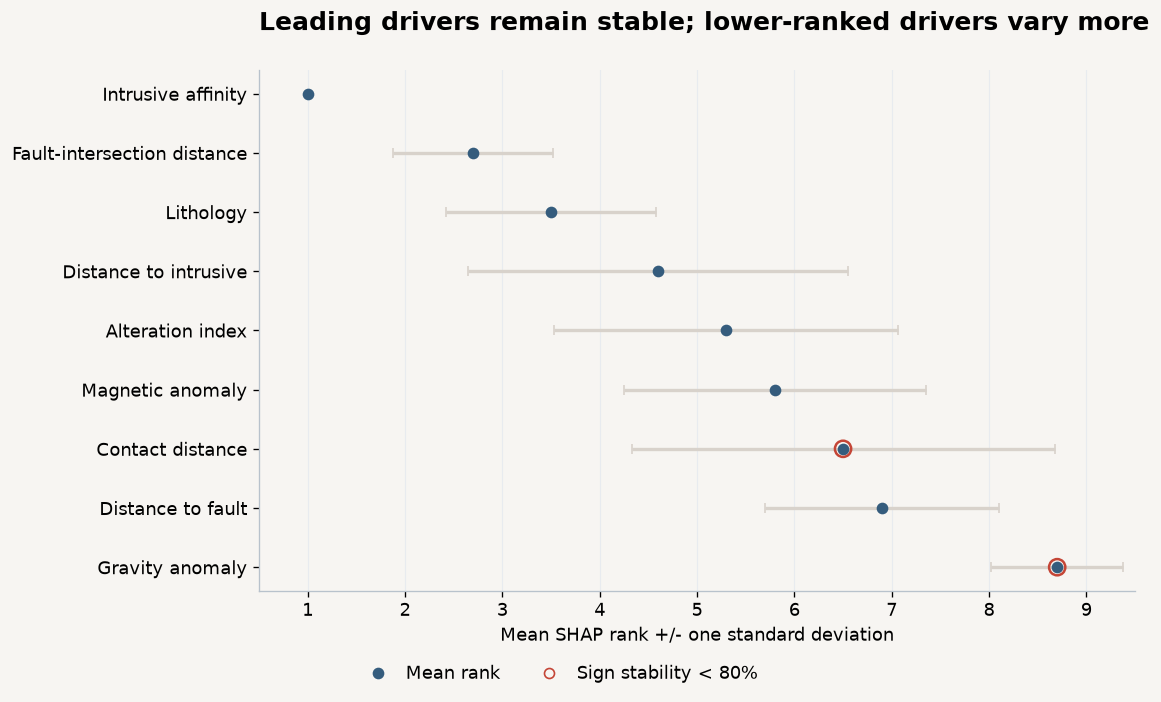

In [15]:
stability_plot = stability.sort_values(
    "rank_mean",
    ascending=False,
).copy()
stability_plot["label"] = stability_plot["feature"].map(
    pretty_feature
)

fig, ax = plt.subplots(figsize=(10.0, 6.2))

y = np.arange(len(stability_plot))

ax.errorbar(
    stability_plot["rank_mean"],
    y,
    xerr=stability_plot["rank_std"],
    fmt="o",
    color=TRUST,
    ecolor=NEUTRAL,
    elinewidth=2.0,
    capsize=3,
    markersize=6,
)

for index, row in stability_plot.reset_index(
    drop=True
).iterrows():
    if row["sign_stability"] < 0.8:
        ax.scatter(
            row["rank_mean"],
            index,
            s=95,
            facecolors="none",
            edgecolors=ACCENT,
            linewidth=1.5,
            zorder=4,
        )

ax.set_yticks(y)
ax.set_yticklabels(stability_plot["label"])
ax.set_xlabel("Mean SHAP rank +/- one standard deviation")
ax.set_xlim(0.5, 9.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
clean_axis(ax)
ax.set_title(
    "Leading drivers remain stable; lower-ranked drivers vary more",
    loc="left",
    pad=24,
)

legend = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=TRUST,
        markeredgecolor=TRUST,
        label="Mean rank",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="none",
        markeredgecolor=ACCENT,
        label="Sign stability < 80%",
    ),
]
fig.legend(
    handles=legend,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=2,
    frameon=False,
    columnspacing=1.8,
    handletextpad=0.6,
)

fig.subplots_adjust(
    left=0.25,
    right=0.98,
    top=0.86,
    bottom=0.16,
)
plt.show()

In [16]:
stability_table = stability.copy()
stability_table["Feature"] = stability_table["feature"].map(
    pretty_feature
)
stability_table = stability_table[
    [
        "Feature",
        "rank_mean",
        "rank_std",
        "sign_stability",
        "stable_top5_fraction",
    ]
].rename(
    columns={
        "rank_mean": "Mean rank",
        "rank_std": "Rank SD",
        "sign_stability": "Sign stability",
        "stable_top5_fraction": "Top-5 frequency",
    }
)

format_table(
    stability_table,
    {
        "Mean rank": lambda x: f"{x:.1f}",
        "Rank SD": lambda x: f"{x:.2f}",
        "Sign stability": lambda x: f"{x:.0%}",
        "Top-5 frequency": lambda x: f"{x:.0%}",
    },
)

Feature,Mean rank,Rank SD,Sign stability,Top-5 frequency
Intrusive affinity,1.0,0.00,100%,100%
Fault-intersection distance,2.7,0.82,100%,100%
Lithology,3.5,1.08,80%,100%
Distance to intrusive,4.6,1.96,80%,60%
Alteration index,5.3,1.77,100%,50%
Magnetic anomaly,5.8,1.55,100%,40%
Contact distance,6.5,2.17,60%,30%
Distance to fault,6.9,1.20,100%,20%
Gravity anomaly,8.7,0.67,50%,0%


## 7. Scientific interpretation

Three conclusions survive the full explanation stack.

1. **Intrusive context is consistently central.** Intrusive
   affinity ranks first under permutation importance and SHAP and
   remains highly stable across background replicates.
2. **Structural context matters, but attribution is distributed.**
   Fault-intersection distance is consistently important, while
   contact and fault distances are more variable.
3. **Agreement does not erase uncertainty.** Lower-ranked
   geophysical and distance variables show greater rank or sign
   instability. These differences are retained rather than hidden.

The analysis remains associative. Spatial coherence, SHAP
attribution, coefficient sign, and permutation degradation do not
establish geological causation.

## 8. Publication boundary

This laboratory uses synthetic data and a deliberately frozen
public model contract. Hidden-oracle labels are not used to build
or tune explanations.

The notebook is intended as a reproducible portfolio artifact for
demonstrating:

- leakage-aware explainability;
- OOS ensemble interpretation;
- global, local, and spatial XAI;
- cross-method agreement;
- stability analysis;
- explicit distinction between predictive attribution and causality.

## Key takeaway

**Explainable GeoAI is most useful when the explanation process
inherits the same validation and out-of-sample constraints as the
predictive model itself.**

Here, explanation is not an ornamental plot added after modeling.
It is treated as a validated analytical layer with its own
contracts, stability checks, and interpretation limits.